# Risk-Aware Resolution Allocation for ViLT

**Reference paper:** [ViLT: Vision-and-Language Transformer Without Convolution or Region Supervision](https://arxiv.org/abs/2102.03334)

This project investigates whether selecting image resolution based on question characteristics can reduce visual patch usage while preserving VQA performance.

We use a pretrained ViLT-B/32 model without changing its weights and compare 384 and 256 image resolutions on VQAv2. Our experiments evaluate fixed-resolution baselines, random allocation, category-based selection, and the proposed Risk-Aware method under different visual patch budgets.

In [11]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/YZM5110_ViLT_Risk_Aware')
for name in ('inputs', 'metadata', 'predictions', 'metrics', 'figures'):
    (PROJECT_DIR / name).mkdir(parents=True, exist_ok=True)
print(f'Artifacts will be saved under {PROJECT_DIR}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artifacts will be saved under /content/drive/MyDrive/YZM5110_ViLT_Risk_Aware


## Configure the runtime and official data



In [12]:
from contextlib import contextmanager
from urllib.parse import urljoin, urlsplit
import io
from importlib.metadata import PackageNotFoundError, version
from uuid import uuid4
import csv
import hashlib
import json
import os
import re
import shutil
import subprocess
import sys
import zipfile

RUN_SIZE = 'LARGE'  # Choose SMALL, MEDIUM, or LARGE.
RUN_SIZES = {'SMALL': (200, 300), 'MEDIUM': (500, 1000), 'LARGE': (1000, 2000)}
if RUN_SIZE not in RUN_SIZES:
    raise ValueError(f'RUN_SIZE must be one of {", ".join(RUN_SIZES)}; got {RUN_SIZE!r}.')
n_dev, n_test = RUN_SIZES[RUN_SIZE]
max_dev, max_test = RUN_SIZES['LARGE']

CONFIG = {
    'seed': 5110, 'run_size': RUN_SIZE, 'n_dev': n_dev, 'n_test': n_test,
    'split_protocol': 'fixed_dev_and_final_pools_v1',
    'standard': 384, 'low': 256, 'budget_fractions': [0.60, 0.75, 0.90],
    'shrinkage_groups': 15, 'random_seeds': list(range(5110, 5130)),
    'bootstrap_draws': 2000, 'profile_images': 24,
    'model_id': 'dandelin/vilt-b32-finetuned-vqa',
    'revision': 'd0a1f6ab88522427a7ae76ceb6e1e1e7b68a1d08',
    'protocol_version': 2,
}
PINS = {'transformers': '5.7.0', 'huggingface-hub': '1.13.0',
        'tokenizers': '0.22.2', 'safetensors': '0.7.0'}
missing = []
for package, pin in PINS.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed != pin:
        missing.append(f'{package}=={pin}')
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
                    *missing], check=True)

import numpy as np
import requests
import torch
import torchvision
from packaging.version import Version
from PIL import Image
from tqdm.auto import tqdm
from urllib3.util.retry import Retry

if Version(torch.__version__.split('+')[0]) < Version('2.6'):
    raise RuntimeError('Select a current Colab runtime (PyTorch >= 2.6 for this .bin checkpoint).')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
runtime_info = {'python': sys.version.split()[0], 'device': device, 'torch': torch.__version__,
                'gpu': torch.cuda.get_device_name() if device == 'cuda' else None,
                'cuda': torch.version.cuda, 'torchvision': torchvision.__version__,
                'numpy': np.__version__, 'pillow': version('pillow'),
                **{k: version(k) for k in PINS}}
if device == 'cpu':
    print(f'CUDA unavailable. Using all {n_dev + n_test:,} {RUN_SIZE} examples on CPU; '
          'select a GPU runtime for GPU timings.')
    torch.set_num_threads(min(os.cpu_count() or 1, 4))
torch.manual_seed(CONFIG['seed'])
S3 = 'https://cvmlp.s3.amazonaws.com/vqa/mscoco/vqa'
URLS = {'questions.zip': f'{S3}/v2_Questions_Val_mscoco.zip',
        'annotations.zip': f'{S3}/v2_Annotations_Val_mscoco.zip'}
COCO_DIRECT = 'https://images.cocodataset.org/val2014/'
# This exact public revision advertises the same SHA-256 as TFDS's original COCO ZIP.
COCO_ZIP = ('https://huggingface.co/tianweiy/DMD2/resolve/'
            '5d3045a8940baea376fb2d8b0ff56c330d76fec0/data/coco/val2014.zip')
COCO_ZIP_BYTES = 6645013297
COCO_ZIP_SHA256 = 'fe9be816052049c34717e077d9e34aa60814a55679f804cd043e3cbee3b9fde0'
COCO_SAMPLE_ID = 471273
inputs_dir = PROJECT_DIR / 'inputs'
images_dir = inputs_dir / 'val2014'
images_dir.mkdir(exist_ok=True)

def save_json(path, value):
    partial = path.with_suffix(f'{path.suffix}.{uuid4().hex}.part')
    partial.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n',
                       encoding='utf-8')
    partial.replace(path)

def save_csv(path, rows, columns=None):
    partial = path.with_suffix(f'{path.suffix}.{uuid4().hex}.part')
    with partial.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns or list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    partial.replace(path)

def sha_file(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def stable_hash(*values):
    return hashlib.sha256('|'.join(map(str, values)).encode('ascii')).hexdigest()

def https_get(client, url, **kwargs):
    """Follow only HTTPS redirects with normal certificate and hostname checks."""
    for _ in range(8):
        if urlsplit(url).scheme != 'https':
            raise ValueError(f'Refusing a non-HTTPS download: {url}')
        response = client.get(url, stream=True, timeout=(15, 90), verify=True,
                              allow_redirects=False, **kwargs)
        if not response.is_redirect:
            return response
        next_url = urljoin(url, response.headers['Location'])
        response.close()
        url = next_url
    raise requests.TooManyRedirects('Too many HTTPS download redirects.')

def download(path, urls, verify=None):
    if path.exists():
        if verify:
            verify(path)
        return
    partial = path.with_suffix(f'{path.suffix}.{uuid4().hex}.part')
    errors = []
    for url in urls:
        for _ in range(2):
            try:
                with https_get(requests, url) as response:
                    response.raise_for_status()
                    with partial.open('wb') as output:
                        for chunk in response.iter_content(1024 * 1024):
                            output.write(chunk)
                if verify:
                    verify(partial)
                partial.replace(path)
                return
            except (OSError, requests.RequestException) as error:
                errors.append(f'{url}: {error}')
                partial.unlink(missing_ok=True)
    raise RuntimeError(f'Official input {path.name} could not be retrieved. '
                       f'Retry the cell or place the official file in {path.parent}.\n'
                       + '\n'.join(errors))

def zip_rows(path, key):
    with zipfile.ZipFile(path) as archive:
        names = [name for name in archive.namelist() if name.endswith('.json')]
        if len(names) != 1:
            raise ValueError(f'Expected one JSON file in {path}, got {names}')
        return json.loads(archive.read(names[0]))[key]

for name, url in URLS.items():
    print(f'Checking official VQAv2 source: {name}')
    download(inputs_dir / name, [url])
question_rows = zip_rows(inputs_dir / 'questions.zip', 'questions')
annotation_rows = zip_rows(inputs_dir / 'annotations.zip', 'annotations')
annotations = {row['question_id']: row for row in annotation_rows}
if len(annotations) != len(annotation_rows) or len({row['question_id'] for row in question_rows}) != len(question_rows):
    raise ValueError('The official VQAv2 inputs contain duplicate question IDs.')
if len(question_rows) != len(annotations) or {r['question_id'] for r in question_rows} != annotations.keys():
    raise ValueError('The official question and answer files have different lengths.')

# Fixed image sample, then one question per selected image. No label filtering.
by_image = {}
for row in question_rows:
    qid, image_id = row['question_id'], row['image_id']
    annotation = annotations[qid]
    if image_id != annotation['image_id'] or (len(annotation['answers']) != 10 or len({a['answer_id'] for a in annotation['answers']}) != 10):
        raise ValueError(f'Invalid image or annotator mapping for {qid}')
    rank = stable_hash('question', CONFIG['seed'], qid)
    if image_id not in by_image or rank < by_image[image_id][0]:
        by_image[image_id] = (rank, row)
image_ids = sorted(by_image, key=lambda i: (stable_hash('image', CONFIG['seed'], i), i))
if len(image_ids) < max_dev + max_test:
    raise ValueError('Not enough official validation images for the fixed LARGE pools.')
# Define image roles once. Changing RUN_SIZE only changes the prefix in each pool.
dev_pool = image_ids[:max_dev]
test_pool = image_ids[max_dev:max_dev + max_test]
if set(dev_pool) & set(test_pool):
    raise ValueError('The fixed development and final pools overlap.')
master_split = [
    {'split': split, 'pool_rank': rank, 'image_id': image_id,
     'question_id': by_image[image_id][1]['question_id']}
    for split, pool in (('dev', dev_pool), ('test', test_pool))
    for rank, image_id in enumerate(pool, start=1)
]
source_hashes = {name: sha_file(inputs_dir / name) for name in URLS}
split_signature = {'protocol': CONFIG['split_protocol'], 'seed': CONFIG['seed'],
                   'source_sha256': source_hashes, 'master_split': master_split}
split_id = hashlib.sha256(json.dumps(split_signature, sort_keys=True).encode()).hexdigest()
split_dir = PROJECT_DIR / 'metadata' / 'splits'
split_dir.mkdir(exist_ok=True)
save_csv(split_dir / f'{split_id}.csv', master_split)

dev_rows = [{**by_image[i][1], 'split': 'dev'} for i in dev_pool[:n_dev]]
test_rows = [{**by_image[i][1], 'split': 'test'} for i in test_pool[:n_test]]
rows = dev_rows + test_rows
assert len(dev_rows) == n_dev and len(test_rows) == n_test

def verify_jpeg(path):
    with Image.open(path) as image:
        if image.format != 'JPEG' or min(image.size) <= 0:
            raise OSError(f'Expected a nonempty COCO JPEG: {path}')
        image.verify()

class CocoZipRanges(io.RawIOBase):
    """Seekable, bounded HTTPS reads for zipfile. Reject any full-object response."""

    def __init__(self, session):
        super().__init__()
        self.session = session
        self.position = 0

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.position

    def seek(self, offset, whence=io.SEEK_SET):
        base = {io.SEEK_SET: 0, io.SEEK_CUR: self.position, io.SEEK_END: COCO_ZIP_BYTES}
        position = base[whence] + offset
        if position < 0:
            raise OSError('Cannot seek before the start of the COCO archive.')
        self.position = position
        return position

    def readinto(self, buffer):
        start = self.position
        size = min(len(buffer), max(0, COCO_ZIP_BYTES - start))
        if not size:
            return 0
        if size > 16 * 1024**2:
            raise OSError('COCO archive range exceeds the 16 MiB request limit.')
        end = start + size - 1
        expected = f'bytes {start}-{end}/{COCO_ZIP_BYTES}'
        with https_get(self.session, COCO_ZIP, headers={
            'Range': f'bytes={start}-{end}', 'Accept-Encoding': 'identity',
        }) as response:
            if response.status_code != 206 or response.headers.get('Content-Range') != expected:
                raise OSError(f'COCO archive range failed (HTTP {response.status_code}, '
                              f'Content-Range {response.headers.get("Content-Range")!r}).')
            contents = response.raw.read(size)
        if len(contents) != size:
            raise OSError(f'Incomplete COCO archive range at offset {start}.')
        buffer[:size] = contents
        self.position += size
        return size

@contextmanager
def open_coco_zip():
    staged = inputs_dir / 'val2014.zip'
    if staged.is_file():
        if staged.stat().st_size != COCO_ZIP_BYTES or sha_file(staged) != COCO_ZIP_SHA256:
            raise ValueError(f'{staged} does not match the original COCO val2014 ZIP.')
        with zipfile.ZipFile(staged) as archive:
            yield archive
        return
    with requests.Session() as session:
        retry = Retry(total=3, backoff_factor=1, status_forcelist=(429, 500, 502, 503, 504))
        session.mount('https://', requests.adapters.HTTPAdapter(max_retries=retry))
        with io.BufferedReader(CocoZipRanges(session), buffer_size=256 * 1024) as remote:
            with zipfile.ZipFile(remote) as archive:
                yield archive

def coco_filename(image_id):
    return f'COCO_val2014_{image_id:012d}.jpg'

def extract_coco_jpeg(archive, name, path):
    partial = path.with_suffix(f'{path.suffix}.{uuid4().hex}.part')
    try:
        # Exact original member name; zipfile checks its CRC on complete reads.
        with archive.open(f'val2014/{name}') as image, partial.open('wb') as output:
            shutil.copyfileobj(image, output)
        verify_jpeg(partial)
        partial.replace(path)
    finally:
        partial.unlink(missing_ok=True)

def fetch_image(row):
    name = coco_filename(row['image_id'])
    path = images_dir / name
    verify_jpeg(path)
    with Image.open(path) as image:
        width, height = image.size
    return {**row, 'source_width': width, 'source_height': height, 'image_sha256': sha_file(path)}

def cache_coco_images(cohort):
    if not globals().get('coco_preflight'):
        raise RuntimeError('Run the exact COCO JPEG preflight successfully before fetching the cohort.')
    missing = list(dict.fromkeys(coco_filename(row['image_id']) for row in cohort
                                 if not (images_dir / coco_filename(row['image_id'])).is_file()))
    if coco_preflight['transport'] == 'official_https':
        for name in tqdm(missing, desc='Official COCO HTTPS'):
            try:
                download(images_dir / name, [COCO_DIRECT + name], verify=verify_jpeg)
            except RuntimeError as error:
                print(f'Switching to the Hugging Face archive: {error}')
                break
    missing = [name for name in missing if not (images_dir / name).is_file()]
    if missing:
        try:
            with open_coco_zip() as archive:
                ordered = sorted(missing, key=lambda name: archive.getinfo(f'val2014/{name}').header_offset)
                for name in tqdm(ordered, desc='COCO archive members'):
                    extract_coco_jpeg(archive, name, images_dir / name)
        except (OSError, ValueError, KeyError, zipfile.BadZipFile, requests.RequestException) as error:
            raise RuntimeError(f'Could not retrieve the remaining COCO JPEGs: {error}. '
                               f'Completed JPEGs are cached. Retry or stage the original '
                               f'archive at {inputs_dir / "val2014.zip"}.') from error
    return [fetch_image(row) for row in tqdm(cohort, desc='Validate locked COCO images')]


Checking official VQAv2 source: questions.zip
Checking official VQAv2 source: annotations.zip


In [13]:
# Verify this exact source JPEG in Colab before any cohort JPEG is fetched.
coco_preflight = None
sample_name = coco_filename(COCO_SAMPLE_ID)
sample_path = images_dir / sample_name
probe_path = images_dir / f'.preflight-{uuid4().hex}.jpg'
def verify_probe(path):
    verify_jpeg(path)
    with Image.open(path) as image:
        image.load()

try:
    direct_error = None
    try:
        download(probe_path, [COCO_DIRECT + sample_name], verify=verify_probe)
        transport = 'official_https'
    except RuntimeError as error:
        direct_error = str(error)
        print('Official HTTPS probe failed. Checking the pinned Hugging Face archive.')
        try:
            with open_coco_zip() as archive:
                extract_coco_jpeg(archive, sample_name, probe_path)
            transport = ('staged_zip' if (inputs_dir / 'val2014.zip').is_file()
                         else 'hugging_face_zip_ranges')
        except (OSError, ValueError, KeyError, zipfile.BadZipFile, requests.RequestException) as zip_error:
            raise RuntimeError(f'COCO preflight failed for {sample_name}. No cohort JPEGs requested. '
                               f'Archive error: {zip_error}. Official host error: {direct_error}\n'
                               f'Retry in Colab or stage the original ZIP at {inputs_dir / "val2014.zip"}.') from zip_error
    with Image.open(probe_path) as sample_image:
        sample_image.load()
        sample_size = sample_image.size
    sample_digest = sha_file(probe_path)
    if sample_path.is_file() and sha_file(sample_path) != sample_digest:
        raise ValueError(f'Existing {sample_path} differs from the verified source JPEG. '
                         'Move the existing file out of the cache and rerun preflight.')
    if not sample_path.is_file():
        probe_path.replace(sample_path)
    coco_preflight = {'filename': sample_name, 'image_id': COCO_SAMPLE_ID,
                      'transport': transport, 'dimensions': list(sample_size),
                      'jpeg_sha256': sample_digest, 'archive_url': COCO_ZIP,
                      'published_archive_sha256': COCO_ZIP_SHA256}
    save_json(PROJECT_DIR / 'metadata' / 'coco_preflight.json', coco_preflight)
    print(f'COCO preflight passed: {sample_name} ({sample_size[0]}×{sample_size[1]}) via {transport}.')
    print(f'Sample JPEG SHA-256: {sample_digest}')
finally:
    probe_path.unlink(missing_ok=True)


Official HTTPS probe failed. Checking the pinned Hugging Face archive.
COCO preflight passed: COCO_val2014_000000471273.jpg (640×480) via hugging_face_zip_ranges.
Sample JPEG SHA-256: 51b971a4d6f5a85359b6abfe4456590f1ee32445ae6d2519d6f98dd47447b590


## Load the frozen model, instrument encoder shapes, and define VQA scoring



In [14]:
from copy import deepcopy
from time import perf_counter
from huggingface_hub import snapshot_download
from transformers import ViltForQuestionAnswering, ViltProcessor
from transformers.models.vilt.image_processing_vilt import MAX_LONGER_EDGE, MAX_SHORTER_EDGE

checkpoint_dir = inputs_dir / 'checkpoints' / CONFIG['revision']
model_files = ('config.json', 'pytorch_model.bin', 'preprocessor_config.json',
               'tokenizer_config.json', 'special_tokens_map.json', 'tokenizer.json', 'vocab.txt')
try:
    if not all((checkpoint_dir / name).is_file() for name in model_files):
        snapshot_download(repo_id=CONFIG['model_id'], revision=CONFIG['revision'],
                          local_dir=checkpoint_dir, allow_patterns=list(model_files))
    local_checkpoint = Path('/content/vilt_risk_aware_checkpoint') / CONFIG['revision']
    local_checkpoint.mkdir(parents=True, exist_ok=True)
    for name in model_files:
        source, target = checkpoint_dir / name, local_checkpoint / name
        if not target.is_file() or target.stat().st_size != source.stat().st_size:
            partial = target.with_suffix(target.suffix + '.part')
            shutil.copyfile(source, partial)
            partial.replace(target)
    processor = ViltProcessor.from_pretrained(local_checkpoint, local_files_only=True)
    model, load_info = ViltForQuestionAnswering.from_pretrained(
        local_checkpoint, local_files_only=True, output_loading_info=True)
except Exception as error:
    raise RuntimeError(f'Could not load {CONFIG["model_id"]}@{CONFIG["revision"]}. '
                       f'Check the runtime libraries and Hugging Face access: {error}') from error
if load_info.get('missing_keys') or load_info.get('mismatched_keys'):
    raise ValueError(f'The published checkpoint did not initialize all ViLT weights: {load_info}')
model = model.to(device).eval().requires_grad_(False)
label_map = model.config.id2label
patch_size = model.config.patch_size
text_limit = model.config.max_position_embeddings
image_config = processor.image_processor
if (sorted(label_map) != list(range(3129)) or model.config.num_labels != 3129
        or patch_size != 32 or image_config.size_divisor != patch_size
        or image_config.size['shortest_edge'] != CONFIG['standard']
        or not image_config.do_resize or not image_config.do_normalize
        or model.config.max_image_length not in (-1, None)):
    raise ValueError('Unexpected label map, standard preprocessing, or capped patch configuration.')
low_processor = deepcopy(processor)
low_processor.image_processor.size = {'shortest_edge': CONFIG['low']}
processors = {CONFIG['standard']: processor, CONFIG['low']: low_processor}
checkpoint_file_hashes = {name: sha_file(local_checkpoint / name) for name in model_files}
checkpoint_hash = checkpoint_file_hashes['pytorch_model.bin']
# Exclude experiment size, split, policy, and labels from the prediction identity.
cache_signature = {
    'format': 'per_example_v1', 'model_id': CONFIG['model_id'], 'revision': CONFIG['revision'],
    'checkpoint_files_sha256': checkpoint_file_hashes, 'environment': runtime_info,
    'seed': CONFIG['seed'], 'batch_size': 1, 'dtype': str(next(model.parameters()).dtype),
    'matmul_tf32': torch.backends.cuda.matmul.allow_tf32,
    'cudnn_tf32': torch.backends.cudnn.allow_tf32,
    'text_limit': text_limit, 'max_image_length': model.config.max_image_length,
    'image_processors': {edge: p.image_processor.to_dict() for edge, p in processors.items()},
}
cache_id = hashlib.sha256(json.dumps(cache_signature, sort_keys=True).encode()).hexdigest()
shared_predictions = PROJECT_DIR / 'predictions' / 'shared_cache' / cache_id
shared_predictions.mkdir(parents=True, exist_ok=True)
save_json(shared_predictions / 'provenance.json', cache_signature)
checkpoint_info = {
    'model': CONFIG['model_id'], 'revision': CONFIG['revision'], 'load_info': str(load_info),
    'standard_processor': image_config.to_dict(), 'low_processor': low_processor.image_processor.to_dict(),
    'label_count': len(label_map), 'patch_size': patch_size,
    'text_limit': text_limit, 'max_image_length': model.config.max_image_length,
    'checkpoint_sha256': checkpoint_hash, 'prediction_cache_id': cache_id,
}

def grid_shape(width, height, edge):
    """Geometry only, matching the pinned processor's rounding and aspect cap."""
    longer_cap = int(MAX_LONGER_EDGE / MAX_SHORTER_EDGE * edge)
    if height < width:
        h, w = edge, width * (edge / height)
    else:
        h, w = height * (edge / width), edge
    if max(h, w) > longer_cap:
        scale = longer_cap / max(h, w)
        h, w = h * scale, w * scale
    h, w = int(h + 0.5) // patch_size, int(w + 0.5) // patch_size
    if min(h, w) < 1:
        raise ValueError(f'The processor cannot fit a complete patch for {width}x{height}, edge {edge}.')
    return h, w

encoder_shape = {}
def observe_encoder(_module, args):
    encoder_shape['length'] = int(args[0].shape[1])

encoder_hook = model.vilt.encoder.register_forward_pre_hook(observe_encoder)

def predict_one(row, edge):
    """One real image/question, one frozen forward. Batch size one everywhere."""
    torch.manual_seed((CONFIG['seed'] + int(row['question_id'])) % 2**32)
    gpu = device == 'cuda'
    if gpu:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        gpu_start = torch.cuda.Event(enable_timing=True)
        gpu_stop = torch.cuda.Event(enable_timing=True)
    started = perf_counter()
    image_path = images_dir / f'COCO_val2014_{row["image_id"]:012d}.jpg'
    with Image.open(image_path) as opened:
        image = opened.convert('RGB')
    batch = processors[edge](images=image, text=row['question'], padding=False,
                            truncation=True, max_length=text_limit, return_tensors='pt')
    h_grid, w_grid = grid_shape(row['source_width'], row['source_height'], edge)
    actual_h, actual_w = batch['pixel_values'].shape[-2:]
    patches = int(batch['pixel_mask'].sum().item()) // (patch_size ** 2)
    text_tokens = int(batch['input_ids'].shape[1])
    if (actual_h, actual_w, patches) != (h_grid * patch_size, w_grid * patch_size, h_grid * w_grid):
        raise RuntimeError(f'Processor/geometry mismatch for {row["question_id"]} at {edge}: '
                           f'processor={(actual_h, actual_w, patches)}, grid={(h_grid, w_grid)}')
    batch = batch.to(device)
    encoder_shape.clear()
    if gpu:
        torch.cuda.synchronize()
        gpu_start.record()
    forward_started = perf_counter()
    with torch.inference_mode():
        output = model(**batch).logits
    if gpu:
        gpu_stop.record()
        torch.cuda.synchronize()
    wall_forward = 1000 * (perf_counter() - forward_started)
    forward_ms = gpu_start.elapsed_time(gpu_stop) if gpu else wall_forward
    logits = output.detach().float().cpu().numpy()[0]
    answer_index = int(logits.argmax())
    e2e = 1000 * (perf_counter() - started)
    if (logits.shape != (3129,) or not np.isfinite(logits).all()
            or encoder_shape.get('length') != text_tokens + patches + 1):
        raise RuntimeError(f'Unexpected logits or encoder length for {row["question_id"]}.')
    return logits, {
        'patches': patches, 'encoder_length': encoder_shape['length'], 'text_tokens': text_tokens,
        'height': actual_h, 'width': actual_w, 'forward_ms': forward_ms,
        'wall_forward_ms': wall_forward, 'end_to_end_ms': e2e,
        'peak_allocated_mib': torch.cuda.max_memory_allocated() / 1024**2 if gpu else None,
        'answer': label_map[answer_index],
    }

def prediction_cache_path(row, edge):
    question_hash = hashlib.sha256(row['question'].encode('utf-8')).hexdigest()
    input_hash = stable_hash(question_hash, row['image_sha256'])
    name = f'{row["question_id"]}-{row["image_id"]}-{input_hash}.npz'
    return shared_predictions / str(edge) / name

def collect(cohort, edge):
    """Reuse compatible per-example logits and persist misses atomically."""
    paths = [prediction_cache_path(row, edge) for row in cohort]
    paths[0].parent.mkdir(exist_ok=True)
    existing = {file.name for file in paths[0].parent.glob('*.npz')}
    result = []
    hits = 0
    for row, path in tqdm(zip(cohort, paths), total=len(cohort),
                          desc=f'{cohort[0]["split"]} @ {edge}'):
        identity = [row['question_id'], row['image_id'], edge]
        if path.name in existing:
            with np.load(path, allow_pickle=False) as saved:
                logits = saved['logits']
                record = json.loads(saved['record_json'].item())
                if (saved['identity'].tolist() != identity or logits.shape != (3129,)
                        or not np.isfinite(logits).all()
                        or record['answer'] != label_map[int(logits.argmax())]):
                    raise ValueError(f'Invalid prediction cache record: {path}')
            hits += 1
        else:
            logits, record = predict_one(row, edge)
            tmp = path.with_suffix(f'.{uuid4().hex}.part')
            try:
                with tmp.open('wb') as stream:
                    np.savez_compressed(stream, identity=np.array(identity), logits=logits,
                                        record_json=json.dumps(record, allow_nan=False))
                tmp.replace(path)
            finally:
                tmp.unlink(missing_ok=True)
        result.append(record)
    print(f'{cohort[0]["split"]} @ {edge}: {hits:,} reused / {len(cohort) - hits:,} new predictions')
    return result

def timing_summary(records):
    summary = {}
    for key in ('forward_ms', 'wall_forward_ms', 'end_to_end_ms'):
        series = [row[key] for row in records]
        summary[f'{key}_mean'] = float(np.mean(series))
        summary[f'{key}_p50'] = float(np.median(series))
        summary[f'{key}_p95'] = float(np.percentile(series, 95))
    peaks = [row['peak_allocated_mib'] for row in records if row['peak_allocated_mib'] is not None]
    summary['peak_allocated_mib'] = max(peaks) if peaks else None
    return summary

# Port of the GT-Vision-Lab VQAv2 evaluator normalization and scoring.
# https://github.com/GT-Vision-Lab/VQA/blob/master/PythonEvaluationTools/vqaEvaluation/vqaEval.py
CONTRACTIONS = {'aint': "ain't",
 'arent': "aren't",
 'cant': "can't",
 'couldve': "could've",
 'couldnt': "couldn't",
 "couldn'tve": "couldn't've",
 "couldnt've": "couldn't've",
 'didnt': "didn't",
 'doesnt': "doesn't",
 'dont': "don't",
 'hadnt': "hadn't",
 "hadnt've": "hadn't've",
 "hadn'tve": "hadn't've",
 'hasnt': "hasn't",
 'havent': "haven't",
 'hed': "he'd",
 "hed've": "he'd've",
 "he'dve": "he'd've",
 'hes': "he's",
 'howd': "how'd",
 'howll': "how'll",
 'hows': "how's",
 "Id've": "I'd've",
 "I'dve": "I'd've",
 'Im': "I'm",
 'Ive': "I've",
 'isnt': "isn't",
 'itd': "it'd",
 "itd've": "it'd've",
 "it'dve": "it'd've",
 'itll': "it'll",
 "let's": "let's",
 'maam': "ma'am",
 'mightnt': "mightn't",
 "mightnt've": "mightn't've",
 "mightn'tve": "mightn't've",
 'mightve': "might've",
 'mustnt': "mustn't",
 'mustve': "must've",
 'neednt': "needn't",
 'notve': "not've",
 'oclock': "o'clock",
 'oughtnt': "oughtn't",
 "ow's'at": "'ow's'at",
 "'ows'at": "'ow's'at",
 "'ow'sat": "'ow's'at",
 'shant': "shan't",
 "shed've": "she'd've",
 "she'dve": "she'd've",
 "she's": "she's",
 'shouldve': "should've",
 'shouldnt': "shouldn't",
 "shouldnt've": "shouldn't've",
 "shouldn'tve": "shouldn't've",
 "somebody'd": 'somebodyd',
 "somebodyd've": "somebody'd've",
 "somebody'dve": "somebody'd've",
 'somebodyll': "somebody'll",
 'somebodys': "somebody's",
 'someoned': "someone'd",
 "someoned've": "someone'd've",
 "someone'dve": "someone'd've",
 'someonell': "someone'll",
 'someones': "someone's",
 'somethingd': "something'd",
 "somethingd've": "something'd've",
 "something'dve": "something'd've",
 'somethingll': "something'll",
 'thats': "that's",
 'thered': "there'd",
 "thered've": "there'd've",
 "there'dve": "there'd've",
 'therere': "there're",
 'theres': "there's",
 'theyd': "they'd",
 "theyd've": "they'd've",
 "they'dve": "they'd've",
 'theyll': "they'll",
 'theyre': "they're",
 'theyve': "they've",
 'twas': "'twas",
 'wasnt': "wasn't",
 "wed've": "we'd've",
 "we'dve": "we'd've",
 'weve': "we've",
 'werent': "weren't",
 'whatll': "what'll",
 'whatre': "what're",
 'whats': "what's",
 'whatve': "what've",
 'whens': "when's",
 'whered': "where'd",
 'wheres': "where's",
 'whereve': "where've",
 'whod': "who'd",
 "whod've": "who'd've",
 "who'dve": "who'd've",
 'wholl': "who'll",
 'whos': "who's",
 'whove': "who've",
 'whyll': "why'll",
 'whyre': "why're",
 'whys': "why's",
 'wont': "won't",
 'wouldve': "would've",
 'wouldnt': "wouldn't",
 "wouldnt've": "wouldn't've",
 "wouldn'tve": "wouldn't've",
 'yall': "y'all",
 "yall'll": "y'all'll",
 "y'allll": "y'all'll",
 "yall'd've": "y'all'd've",
 "y'alld've": "y'all'd've",
 "y'all'dve": "y'all'd've",
 'youd': "you'd",
 "youd've": "you'd've",
 "you'dve": "you'd've",
 'youll': "you'll",
 'youre': "you're",
 'youve': "you've"}
MANUALMAP = {'none': '0',
 'zero': '0',
 'one': '1',
 'two': '2',
 'three': '3',
 'four': '4',
 'five': '5',
 'six': '6',
 'seven': '7',
 'eight': '8',
 'nine': '9',
 'ten': '10'}
PUNCT = [';',
 '/',
 '[',
 ']',
 '"',
 '{',
 '}',
 '(',
 ')',
 '=',
 '+',
 '\\',
 '_',
 '-',
 '>',
 '<',
 '@',
 '`',
 ',',
 '?',
 '!']


def clean_space(answer):
    return answer.replace('\n', ' ').replace('\t', ' ').strip()

def normalize_vqa(answer):
    raw = clean_space(answer)
    value = raw
    numeric_comma = re.search(r'(\d)(,)(\d)', raw)
    for mark in PUNCT:
        remove = mark + ' ' in raw or ' ' + mark in raw or numeric_comma
        value = value.replace(mark, '' if remove else ' ')
    value = re.sub(r'(?!<=\d)(\.)(?!\d)', '', value)
    words = (MANUALMAP.get(word, word) for word in value.lower().split())
    return ' '.join(CONTRACTIONS.get(word, word) for word in words
                    if word not in ('a', 'an', 'the'))

def score_answer(answer, references):
    """Official evaluator compatibility, including its conditional normalization."""
    if len(references) != 10:
        raise ValueError('Expected exactly ten VQAv2 annotator answers.')
    refs = [clean_space(ref) for ref in references]
    prediction = clean_space(answer)
    if len(set(refs)) > 1:
        refs = [normalize_vqa(ref) for ref in refs]
        prediction = normalize_vqa(prediction)
    matches = refs.count(prediction)
    return ((10 - matches) * min(matches / 3, 1)
            + matches * min(max(matches - 1, 0) / 3, 1)) / 10


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

## Reproduce Standard ViLT Baseline


In [15]:
standard, low = CONFIG['standard'], CONFIG['low']

def score_predictions(cohort, predictions):
    return np.array([score_answer(output['answer'],
                                 [answer['answer'] for answer in annotations[row['question_id']]['answers']])
                     for row, output in zip(cohort, predictions)], dtype=np.float64)

def stage_summary(scores, predictions):
    return {'examples': len(predictions), 'vqa_score_pct': float(100 * scores.mean()),
            'total_visual_patches': sum(row['patches'] for row in predictions),
            'mean_visual_patches': float(np.mean([row['patches'] for row in predictions])),
            'mean_padded_encoder_length': float(np.mean([row['encoder_length'] for row in predictions])),
            **timing_summary(predictions)}

# The first actual ViLT call uses a real, selected VQAv2/COCO pair at 384.
smoke_row = cache_coco_images(dev_rows[:1])[0]
_, smoke = predict_one(smoke_row, standard)
print('Real smoke prediction:', smoke['answer'], '| patches:', smoke['patches'])
rows = [smoke_row, *cache_coco_images(rows[1:])]
dev_rows, test_rows = rows[:n_dev], rows[n_dev:]
manifest = [{key: row[key] for key in ('question_id', 'image_id', 'split', 'source_width',
                                       'source_height', 'image_sha256')} for row in rows]
signature = {'config': CONFIG, 'environment': runtime_info,
             'source_sha256': source_hashes, 'checkpoint_sha256': checkpoint_hash,
             'master_split_id': split_id, 'prediction_cache_id': cache_id, 'manifest': manifest}
run_id = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()[:16]
meta = PROJECT_DIR / 'metadata' / RUN_SIZE / run_id
pred = PROJECT_DIR / 'predictions' / RUN_SIZE / run_id
metrics = PROJECT_DIR / 'metrics' / RUN_SIZE / run_id
figures = PROJECT_DIR / 'figures' / RUN_SIZE / run_id
for folder in (meta, pred, metrics, figures):
    folder.mkdir(parents=True, exist_ok=True)
save_json(meta / 'configuration.json', {**signature, 'source_urls': URLS, 'coco_image_preflight': coco_preflight,
          'checkpoint_exposure': 'Official checkpoint held-out image list not verified.'})
save_csv(meta / 'manifest.csv', manifest)
print(f'{RUN_SIZE}: {n_dev} development, {n_test} final, one question per image. Run: {run_id}')
save_json(meta / 'checkpoint.json', checkpoint_info)
save_json(meta / 'real_image_smoke_384.json', {'question_id': dev_rows[0]['question_id'],
                                             'image_id': dev_rows[0]['image_id'],
                                             'question': dev_rows[0]['question'], **smoke})
for _ in range(3):
    predict_one(dev_rows[0], standard)
dev_standard = collect(dev_rows, standard)
dev_high_score = score_predictions(dev_rows, dev_standard)
baseline_summary = stage_summary(dev_high_score, dev_standard)
save_json(metrics / '01_original_384_dev.json', baseline_summary)
save_csv(metrics / '01_original_384_dev_predictions.csv', [
    {'question_id': row['question_id'], 'soft_vqa_score': float(score), **record}
    for row, score, record in zip(dev_rows, dev_high_score, dev_standard)])
print('Measured original-checkpoint development baseline:', baseline_summary)


Validate locked COCO images:   0%|          | 0/1 [00:00<?, ?it/s]

Real smoke prediction: kite | patches: 192


COCO archive members:   0%|          | 0/2500 [00:00<?, ?it/s]

Validate locked COCO images:   0%|          | 0/2999 [00:00<?, ?it/s]

LARGE: 1000 development, 2000 final, one question per image. Run: c4447d1bf128a1c5


dev @ 384:   0%|          | 0/1000 [00:00<?, ?it/s]

dev @ 384: 200 reused / 800 new predictions
Measured original-checkpoint development baseline: {'examples': 1000, 'vqa_score_pct': 84.39000000000001, 'total_visual_patches': 197587, 'mean_visual_patches': 197.587, 'mean_padded_encoder_length': 207.939, 'forward_ms_mean': 12.825742787361145, 'forward_ms_p50': 12.795440196990967, 'forward_ms_p95': 13.482710409164428, 'wall_forward_ms_mean': 12.851826357034042, 'wall_forward_ms_p50': 12.820897499295825, 'wall_forward_ms_p95': 13.509329899989098, 'end_to_end_ms_mean': 26.336875645952205, 'end_to_end_ms_p50': 26.395270999273635, 'end_to_end_ms_p95': 28.833576399847516, 'peak_allocated_mib': 474.99951171875}


## Measure Development Resolution Sensitivity



In [16]:
from collections import defaultdict

for _ in range(3):
    predict_one(dev_rows[0], low)
dev_low = collect(dev_rows, low)
dev_low_score = score_predictions(dev_rows, dev_low)
dev_gain = dev_high_score - dev_low_score
for high_row, low_row in zip(dev_standard, dev_low):
    if (high_row['patches'] <= low_row['patches']
            or high_row['encoder_length'] <= low_row['encoder_length']
            or high_row['text_tokens'] != low_row['text_tokens']):
        raise RuntimeError('Resolution did not shorten the visual/joint sequence or changed text length.')
save_json(metrics / '02_resolution_256_dev.json', stage_summary(dev_low_score, dev_low))

# These are pre-inference text features, not VQAv2 annotation fields.
COUNT = re.compile(r'\b(?:how many|how much|number of|count the|quantity of)\b')
COLOR = re.compile(r'\b(?:what colou?r|which colou?r|colou?r of|what shade)\b')
YESNO = re.compile(r'^(?:is|are|was|were|am|do|does|did|has|have|had|can|could|will|would|should)\b')
DETAIL_RULES = (
    ('reading', r'\b(?:what does .{1,50} say|what(?: is the)? (?:word|letter|name|number) (?:on|written)|'
                r'text|written|spelled|license plate|sign say|read|logo|brand)\b'),
    ('fine_detail', r'\b(?:small|tiny|little|farthest|furthest|in the background|far away|'
                    r'corner|pattern|stripe|striped|spot|button|label)\b'),
    ('attribute', r'\b(?:colou?r|shade|shape|material|texture|wearing|made of)\b'),
    ('scene', r'\b(?:indoors|outdoors|inside or outside|day or night|weather|'
               r'what room|what sport|what season|what kind of place)\b'),
)

def text_features(question):
    value = ' '.join(question.lower().strip().split())
    category = ('counting' if COUNT.search(value) else 'color' if COLOR.search(value)
                else 'yes_no' if YESNO.search(value) else 'other')
    # First match gives a transparent and mutually exclusive cue group.
    cue = next((name for name, pattern in DETAIL_RULES if re.search(pattern, value)), 'no_cue')
    return category, cue, bool(YESNO.search(value))

category_values = defaultdict(list)
detail_values = defaultdict(list)
sensitivity_rows = []
for row, high_score, low_score, high_prediction, low_prediction in zip(
        dev_rows, dev_high_score, dev_low_score, dev_standard, dev_low):
    category, detail, yes_no = text_features(row['question'])
    gain = float(high_score - low_score)
    category_values[category].append(gain)
    detail_values[(category, detail)].append(gain)
    sensitivity_rows.append({
        'question_id': row['question_id'], 'category': category, 'detail_group': detail,
        'score_384': float(high_score), 'score_256': float(low_score), 'signed_gain': gain,
        'extra_patches_for_384': high_prediction['patches'] - low_prediction['patches'],
    })
save_csv(metrics / '02_development_sensitivity.csv', sensitivity_rows)

# Hierarchical smoothing of a signed, paired soft-score difference.
# 15 pseudo-examples shrink each rare cue group to the corresponding coarse category.
strength = CONFIG['shrinkage_groups']
global_gain = float(dev_gain.mean())

def shrink(values, parent_mean):
    return (sum(values) + strength * parent_mean) / (len(values) + strength)

category_gain = {name: shrink(gains, global_gain) for name, gains in category_values.items()}
detail_gain = {key: shrink(gains, category_gain[key[0]]) for key, gains in detail_values.items()}
group_rows = []
for name, gains in sorted(category_values.items()):
    group_rows.append({'level': 'category', 'category': name, 'detail_group': '',
                       'n': len(gains), 'raw_mean_gain': float(np.mean(gains)),
                       'smoothed_mean_gain': category_gain[name]})
for (name, cue), gains in sorted(detail_values.items()):
    group_rows.append({'level': 'detail', 'category': name, 'detail_group': cue,
                       'n': len(gains), 'raw_mean_gain': float(np.mean(gains)),
                       'smoothed_mean_gain': detail_gain[(name, cue)]})
save_csv(metrics / '02_development_group_benefit.csv', group_rows)
save_json(meta / 'frozen_policy.json', {
    'target': 'signed VQA soft-score gain at 384 versus 256', 'global_mean_gain': global_gain,
    'pseudo_count': strength, 'groups_from_development_only': group_rows,
    'detail_rules': DETAIL_RULES, 'count_regex': COUNT.pattern,
    'color_regex': COLOR.pattern, 'yesno_regex': YESNO.pattern,
    'fallback': 'unseen detail uses smoothed category; unseen category uses global mean',
    'priority': 'estimated gain divided by extra visual patches',
})
print(f'Dev score gain for 384 vs 256: {100 * global_gain:+.2f} percentage points')
for row in group_rows:
    print(row['category'], row['detail_group'], f'n={row["n"]}',
          f'smoothed gain={row["smoothed_mean_gain"]:+.3f}')


dev @ 256:   0%|          | 0/1000 [00:00<?, ?it/s]

dev @ 256: 200 reused / 800 new predictions
Dev score gain for 384 vs 256: +2.88 percentage points
color  n=85 smoothed gain=+0.041
counting  n=108 smoothed gain=+0.073
other  n=392 smoothed gain=+0.027
yes_no  n=415 smoothed gain=+0.015
color attribute n=84 smoothed gain=+0.044
color fine_detail n=1 smoothed gain=+0.039
counting attribute n=4 smoothed gain=+0.026
counting fine_detail n=2 smoothed gain=+0.117
counting no_cue n=102 smoothed gain=+0.079
other attribute n=23 smoothed gain=+0.069
other fine_detail n=10 smoothed gain=+0.028
other no_cue n=329 smoothed gain=+0.024
other reading n=16 smoothed gain=+0.023
other scene n=14 smoothed gain=+0.014
yes_no attribute n=27 smoothed gain=+0.029
yes_no fine_detail n=2 smoothed gain=+0.013
yes_no no_cue n=384 smoothed gain=+0.013
yes_no scene n=2 smoothed gain=+0.013


## Allocate Visual Patch Budgets

In [17]:
def allocate_exact(costs, priorities, extra_cap):
    """Greedy priority with a reachability check so every comparison spends the same budget.

    A suffix bitset says which integer patch sums can still be reached. Select the
    highest-priority available example if it leaves a feasible exact completion.
    """
    order = sorted(range(len(costs)), key=lambda i: (-float(priorities[i]), i))
    bit_limit = (1 << (extra_cap + 1)) - 1
    suffix = [1] * (len(order) + 1)
    for j in range(len(order) - 1, -1, -1):
        tail = suffix[j + 1]
        suffix[j] = (tail | (tail << int(costs[order[j]]))) & bit_limit
    spend = suffix[0].bit_length() - 1
    remaining = spend
    use_high = np.zeros(len(order), dtype=bool)
    for j, i in enumerate(order):
        left = remaining - int(costs[i])
        if left >= 0 and ((suffix[j + 1] >> left) & 1):
            use_high[i] = True
            remaining = left
    if remaining or int(costs[use_high].sum()) != spend:
        raise RuntimeError('Budget allocator did not produce the intended exact sum.')
    return use_high, spend

routing_started = perf_counter()
test_features = [text_features(row['question']) for row in test_rows]
test_low_cost = np.array([np.prod(grid_shape(row['source_width'], row['source_height'], low))
                          for row in test_rows], dtype=np.int64)
test_high_cost = np.array([np.prod(grid_shape(row['source_width'], row['source_height'], standard))
                           for row in test_rows], dtype=np.int64)
extra_cost = test_high_cost - test_low_cost
if np.any(extra_cost <= 0):
    raise ValueError('Every selected image must save patches at the low resolution.')
full_cost, base_cost = int(test_high_cost.sum()), int(test_low_cost.sum())
category_priority = np.array([category_gain.get(c, global_gain)
                              for c, _, _ in test_features]) / extra_cost
risk_priority = np.array([detail_gain.get((c, d), category_gain.get(c, global_gain))
                          for c, d, _ in test_features]) / extra_cost
routing_setup_ms = 1000 * (perf_counter() - routing_started)
allocation = {}
routing_info = {}
budgets = []
allocation_rows = []

def register(name, mask, fraction=None, seed=None, ranking_ms=0.0):
    allocation[name] = mask
    routing_info[name] = {'budget_target': fraction, 'random_seed': seed,
                          'actual_patches': int(base_cost + extra_cost[mask].sum()),
                          'allocation_ms_full_test': ranking_ms}
    for row, use_high, low_c, high_c in zip(test_rows, mask, test_low_cost, test_high_cost):
        allocation_rows.append({'method': name, 'question_id': row['question_id'],
                                'resolution': standard if use_high else low,
                                'planned_visual_patches': int(high_c if use_high else low_c)})

register('always_384', np.ones(n_test, dtype=bool))
register('always_256', np.zeros(n_test, dtype=bool))
register('yes_no_heuristic', np.array([not yes_no for _, _, yes_no in test_features]))
for budget in CONFIG['budget_fractions']:
    key = str(round(100 * budget))
    cap = int(np.floor(budget * full_cost)) - base_cost
    if cap < 0:
        print(f'Skipping infeasible {budget:.0%} budget: it is below all-low cost.')
        continue
    target_spend = None
    candidates = [f'category_{key}', f'risk_{key}'] + [
        f'random_{key}_{seed}' for seed in CONFIG['random_seeds']]
    for name in candidates:
        start = perf_counter()
        seed = None
        if name.startswith('category'):
            priority = category_priority
        elif name.startswith('risk'):
            priority = risk_priority
        else:
            seed = int(name.rsplit('_', 1)[1])
            priority = np.random.default_rng(seed).random(n_test)
        mask, spend = allocate_exact(extra_cost, priority, cap)
        elapsed = 1000 * (perf_counter() - start)
        if target_spend is None:
            target_spend = spend
        if spend != target_spend or base_cost + spend > budget * full_cost + 1e-9:
            raise AssertionError('Policies did not match realized patch budgets.')
        register(name, mask, budget, seed, elapsed)
    budgets.append({'key': key, 'fraction': budget, 'target_total_patches': int(np.floor(budget * full_cost)),
                    'realized_total_patches': base_cost + target_spend})
if not budgets:
    raise RuntimeError('None of the prescribed budgets is feasible.')
save_csv(meta / 'frozen_final_allocations.csv', allocation_rows)
save_json(meta / 'budget_provenance.json', {
    'all_384': full_cost, 'all_256': base_cost, 'budgets': budgets, 'methods': routing_info,
    'common_text_and_geometry_setup_ms_full_test': routing_setup_ms,
    'tie_order': 'fixed manifest order',
    'random_null': 'seeded random priorities with the same exact-feasibility rule',
    'budget_unit': 'valid visual patches, excluding the visual CLS token',
})
print('Final choices frozen before collecting final predictions or scoring final answers.')
print(budgets)


Final choices frozen before collecting final predictions or scoring final answers.
[{'key': '60', 'fraction': 0.6, 'target_total_patches': 237553, 'realized_total_patches': 237553}, {'key': '75', 'fraction': 0.75, 'target_total_patches': 296942, 'realized_total_patches': 296942}, {'key': '90', 'fraction': 0.9, 'target_total_patches': 356330, 'realized_total_patches': 356330}]


## Evaluate the Locked Final Comparisons

In [18]:
for _ in range(3):
    predict_one(test_rows[0], standard)
test_standard = collect(test_rows, standard)
test_high_score = score_predictions(test_rows, test_standard)
save_json(metrics / '03_original_384_test.json', stage_summary(test_high_score, test_standard))
for _ in range(3):
    predict_one(test_rows[0], low)
test_low = collect(test_rows, low)
test_low_score = score_predictions(test_rows, test_low)
save_json(metrics / '04_fixed_256_test.json', stage_summary(test_low_score, test_low))
if (not np.array_equal(test_high_cost, [row['patches'] for row in test_standard])
        or not np.array_equal(test_low_cost, [row['patches'] for row in test_low])
        or any(a['text_tokens'] != b['text_tokens'] or a['encoder_length'] <= b['encoder_length']
               for a, b in zip(test_standard, test_low))):
    raise AssertionError('Pre-inference patch costs or matched processor inputs did not validate.')

outputs = {}
comparison = []
category_results = []
categories = np.array([c for c, _, _ in test_features])
for name, use_high in allocation.items():
    scores = np.where(use_high, test_high_score, test_low_score)
    lengths = np.where(use_high, [r['encoder_length'] for r in test_standard],
                       [r['encoder_length'] for r in test_low])
    patches = np.where(use_high, test_high_cost, test_low_cost)
    if int(patches.sum()) != routing_info[name]['actual_patches']:
        raise AssertionError(f'Actual patch budget changed for {name}')
    outputs[name] = scores
    comparison.append({
        'method': name, 'final_examples': n_test, 'vqa_score_pct': float(100 * scores.mean()),
        'score_difference_vs_384_pp': float(100 * (scores - test_high_score).mean()),
        'mean_patches': float(patches.mean()), 'pct_of_384_patch_budget': float(100 * patches.sum() / full_cost),
        'mean_encoder_length': float(lengths.mean()), 'total_encoder_positions': int(lengths.sum()),
        'high_resolution_questions': int(use_high.sum()), 'model_forwards_per_question': 1,
        **routing_info[name],
    })
    for cat in sorted(set(categories)):
        group = categories == cat
        category_results.append({
            'method': name, 'category': cat, 'n': int(group.sum()),
            'vqa_score_pct': float(100 * scores[group].mean()),
            'mean_patches': float(patches[group].mean()),
            'high_resolution_fraction': float(use_high[group].mean()),
        })

rng = np.random.default_rng(CONFIG['seed'])
bootstrap_indices = rng.integers(n_test, size=(CONFIG['bootstrap_draws'], n_test))

def paired_summary(difference):
    bootstrap = 100 * difference[bootstrap_indices].mean(axis=1)
    return {'difference_pp': float(100 * difference.mean()),
            'paired_ci95_pp': [float(x) for x in np.percentile(bootstrap, [2.5, 97.5])]}

comparisons_at_budget = []
for budget_spec in budgets:
    key = budget_spec['key']
    random_matrix = np.stack([outputs[f'random_{key}_{seed}'] for seed in CONFIG['random_seeds']])
    risk = outputs[f'risk_{key}']
    category = outputs[f'category_{key}']
    comparisons_at_budget.append({
        **budget_spec, 'random_mean_score_pct': float(100 * random_matrix.mean()),
        'random_seed_score_min_pct': float(100 * random_matrix.mean(axis=1).min()),
        'random_seed_score_max_pct': float(100 * random_matrix.mean(axis=1).max()),
        'risk_minus_random': paired_summary(risk - random_matrix.mean(axis=0)),
        'risk_minus_category': paired_summary(risk - category),
        'risk_minus_always_384': paired_summary(risk - test_high_score),
    })
save_csv(metrics / 'final_method_comparison.csv', comparison)
save_csv(metrics / 'final_by_question_category.csv', category_results)
save_json(metrics / 'matched_budget_effects.json', comparisons_at_budget)
tmp_scores = pred / 'test_score_arrays.part'
with tmp_scores.open('wb') as stream:
    np.savez_compressed(stream, question_id=[row['question_id'] for row in test_rows], **outputs)
tmp_scores.replace(pred / 'test_score_arrays.npz')

# Real paired answer changes; positive, zero, and negative gains remain visible.
cases = []
for i, row in enumerate(test_rows):
    high_score, low_score = float(test_high_score[i]), float(test_low_score[i])
    effect = 'high_helped' if high_score > low_score else 'high_harmed' if high_score < low_score else 'equal_credit'
    cases.append({'question_id': row['question_id'], 'image_id': row['image_id'],
                  'question': row['question'], 'category': test_features[i][0],
                  'detail_group': test_features[i][1], 'effect': effect,
                  'answer_384': test_standard[i]['answer'], 'answer_256': test_low[i]['answer'],
                  'score_384': high_score, 'score_256': low_score,
                  'extra_patches_384': int(extra_cost[i]),
                  'human_answers': ' | '.join(a['answer'] for a in annotations[row['question_id']]['answers'])})
save_csv(metrics / 'paired_resolution_cases.csv', cases)
for effect in ('high_helped', 'high_harmed', 'equal_credit'):
    group = [case for case in cases if case['effect'] == effect]
    print(effect, 'n=', len(group))
    for row in group[:2]:
        print(' ', row['question'], '| 384:', row['answer_384'], row['score_384'],
              '| 256:', row['answer_256'], row['score_256'])
for effect in comparisons_at_budget:
    print(effect)


test @ 384:   0%|          | 0/2000 [00:00<?, ?it/s]

test @ 384: 300 reused / 1,700 new predictions


test @ 256:   0%|          | 0/2000 [00:00<?, ?it/s]

test @ 256: 300 reused / 1,700 new predictions
high_helped n= 174
  How many rolls of toilet  paper? | 384: 1 1.0 | 256: 2 0.0
  What type of shoes is he wearing? | 384: boots 1.0 | 256: sandals 0.0
high_harmed n= 78
  Is the street light straight? | 384: no 0.0 | 256: yes 1.0
  How many keyboards? | 384: 1 0.9 | 256: 2 1.0
equal_credit n= 1748
  What type of room is this? | 384: bedroom 1.0 | 256: bedroom 1.0
  What does the yellow sign say? | 384: nothing 0.0 | 256: nothing 0.0
{'key': '60', 'fraction': 0.6, 'target_total_patches': 237553, 'realized_total_patches': 237553, 'random_mean_score_pct': 77.25925000000001, 'random_seed_score_min_pct': 76.745, 'random_seed_score_max_pct': 77.66000000000003, 'risk_minus_random': {'difference_pp': 0.09075000000000064, 'paired_ci95_pp': [-0.5548187499999993, 0.71359375]}, 'risk_minus_category': {'difference_pp': -0.3, 'paired_ci95_pp': [-0.610125, -0.019999999999999983]}, 'risk_minus_always_384': {'difference_pp': -2.4599999999999995, 'paired_c

## Measure Inference Time and Plot Results

Measure real single-forward policies:   0%|          | 0/24 [00:00<?, ?it/s]

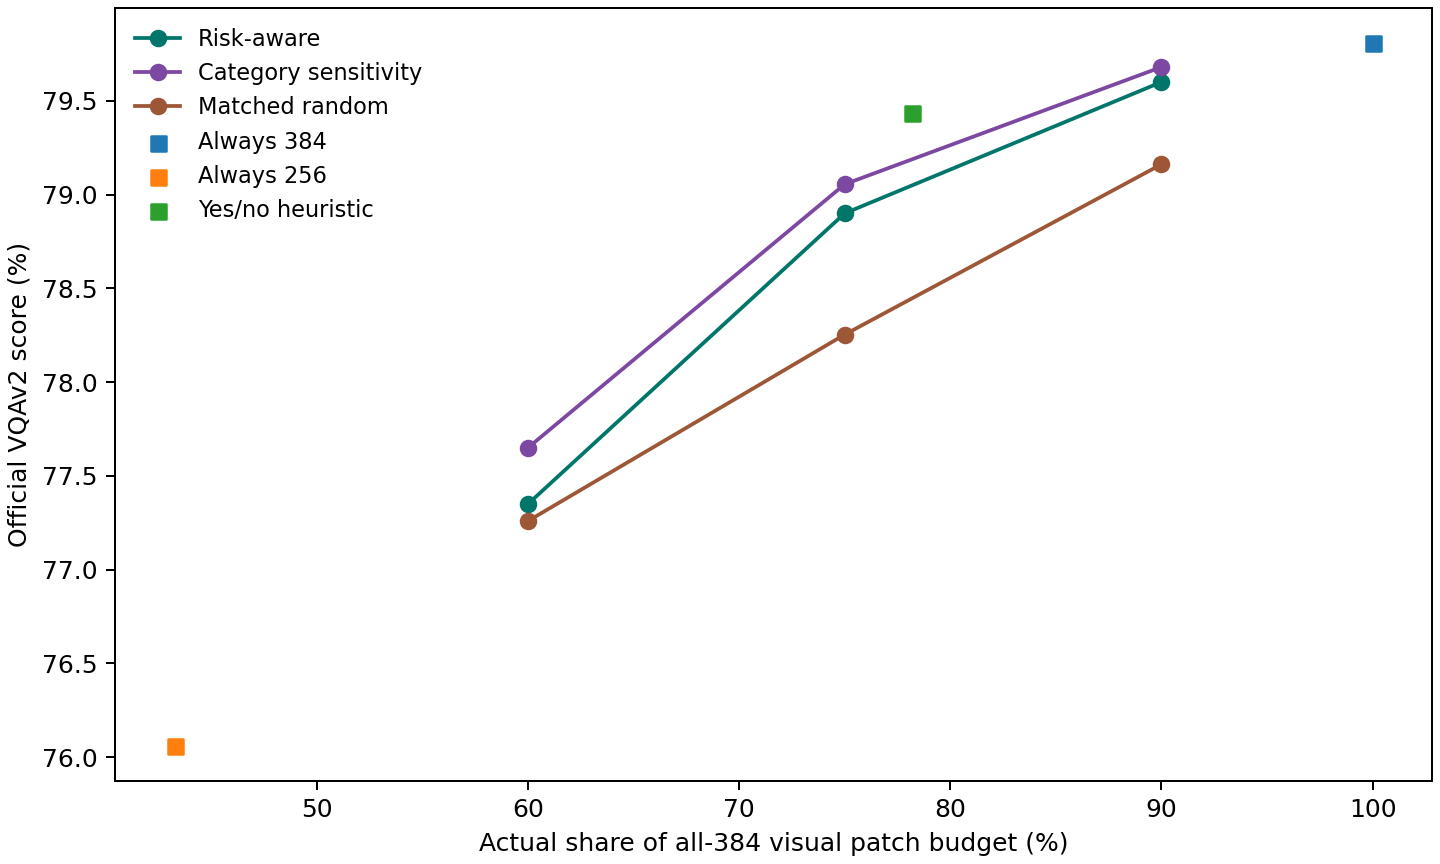

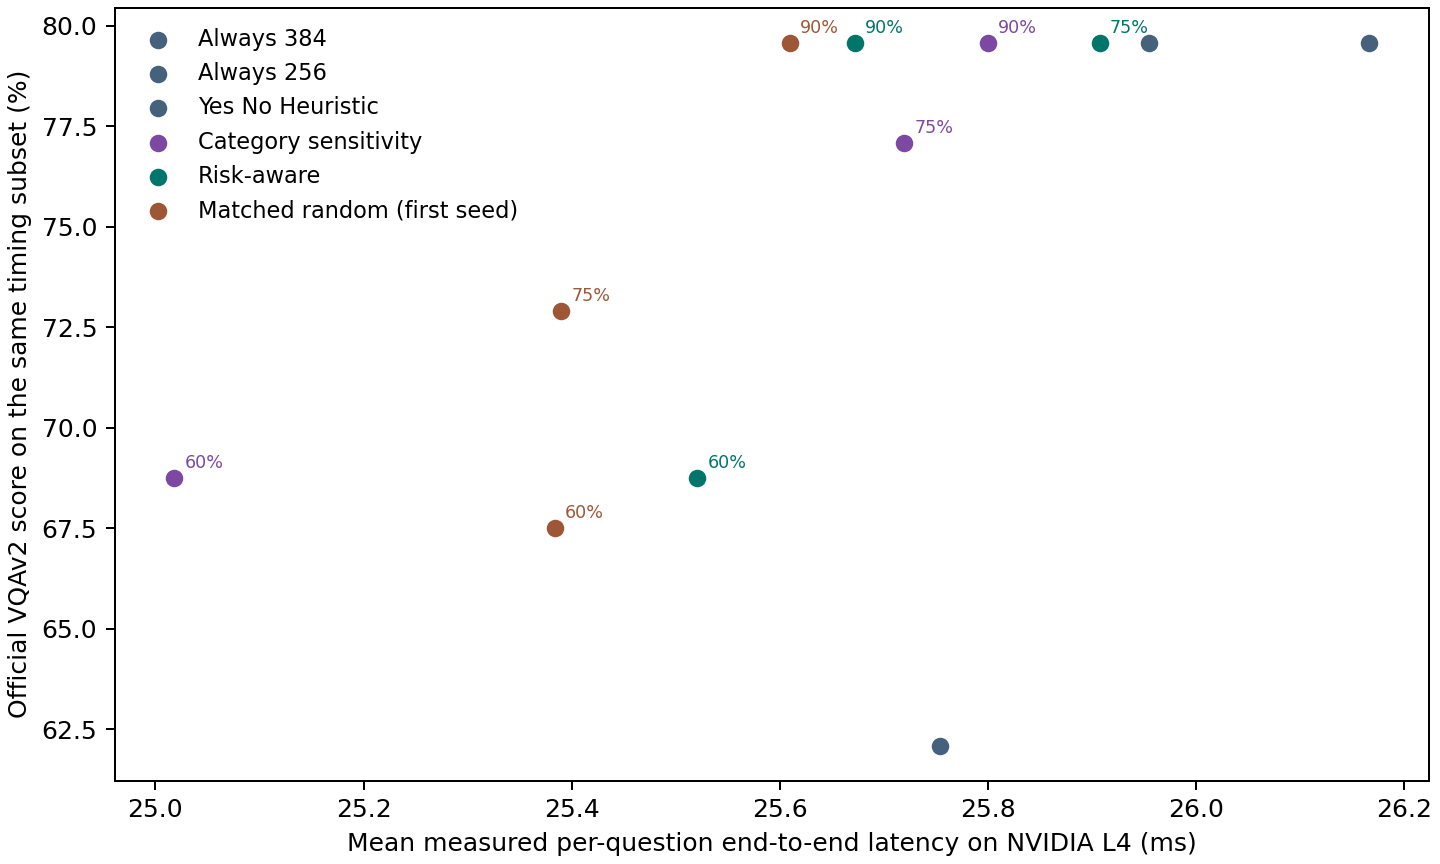

Saved predictions, metrics, policies and figures to /content/drive/MyDrive/YZM5110_ViLT_Risk_Aware (run c4447d1bf128a1c5).


In [19]:
import matplotlib.pyplot as plt
from IPython.display import display, Image as NotebookImage

profile_indices = sorted(range(n_test), key=lambda i: stable_hash(
    'profile', CONFIG['seed'], test_rows[i]['question_id']))[:CONFIG['profile_images']]
profile_methods = ['always_384', 'always_256', 'yes_no_heuristic']
for budget in budgets:
    key = budget['key']
    profile_methods.extend((f'category_{key}', f'risk_{key}', f'random_{key}_{CONFIG["random_seeds"][0]}'))

profile_file = metrics / 'live_policy_forward_rows.json'
profile_name = runtime_info['gpu'] or 'CPU'
if profile_file.is_file():
    live_rows = json.loads(profile_file.read_text())
else:
    live_rows = []
keys = {(r['method'], r['question_id']) for r in live_rows}
# Warm each size on genuine VQAv2 data. Warm-up measurements are discarded.
for edge in (standard, low):
    for i in profile_indices[:3]:
        predict_one(test_rows[i], edge)
for i in tqdm(profile_indices, desc='Measure real single-forward policies'):
    row = test_rows[i]
    # Interleave methods at each question to reduce time-order/device drift.
    order = np.random.default_rng(CONFIG['seed'] + i).permutation(profile_methods)
    for name in order.tolist():
        if (name, row['question_id']) in keys:
            continue
        edge = standard if allocation[name][i] else low
        _, record = predict_one(row, edge)
        live_rows.append({'method': name, 'question_id': row['question_id'],
                          'resolution': edge, **record})
    save_json(profile_file, live_rows)

profile_summary = []
score_by_method = {row['method']: row for row in comparison}
probe_order = [test_rows[i]['question_id'] for i in profile_indices]
for name in profile_methods:
    used = [r for r in live_rows if r['method'] == name]
    if sorted(r['question_id'] for r in used) != sorted(probe_order):
        raise ValueError(f'Live timing rows do not match the profile cohort for {name}.')
    profile_summary.append({
        'method': name, 'device': profile_name, 'profile_examples': len(used),
        'full_test_vqa_score_pct': score_by_method[name]['vqa_score_pct'],
        'profile_vqa_score_pct': float(100 * outputs[name][profile_indices].mean()),
        'profile_mean_patches': float(np.mean([row['patches'] for row in used])),
        'full_cohort_policy_setup_ms': routing_setup_ms,
        'full_cohort_method_allocation_ms': routing_info[name]['allocation_ms_full_test'],
        **timing_summary(used),
    })
save_csv(metrics / 'live_policy_latency.csv', profile_summary)

styles = {'risk': ('#00766b', 'Risk-aware'),
          'category': ('#7c48a2', 'Category sensitivity'),
          'random': ('#9d5736', 'Matched random')}
fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
for prefix, (color, title) in styles.items():
    xs, ys = [], []
    for budget_spec in comparisons_at_budget:
        key = budget_spec['key']
        xs.append(100 * budget_spec['realized_total_patches'] / full_cost)
        ys.append(budget_spec['random_mean_score_pct'] if prefix == 'random'
                  else score_by_method[f'{prefix}_{key}']['vqa_score_pct'])
    ax.plot(xs, ys, 'o-', color=color, label=title)
for name, title in [('always_384', 'Always 384'), ('always_256', 'Always 256'),
                    ('yes_no_heuristic', 'Yes/no heuristic')]:
    item = score_by_method[name]
    ax.scatter(item['pct_of_384_patch_budget'], item['vqa_score_pct'], marker='s', label=title)
ax.set(xlabel='Actual share of all-384 visual patch budget (%)', ylabel='Official VQAv2 score (%)')
ax.legend(frameon=False, fontsize=9)
fig.savefig(figures / 'accuracy_vs_patch_budget.png', dpi=180)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
style_labels = set()
for row in profile_summary:
    name = row['method']
    family = name.split('_')[0]
    color, label = styles.get(family, ('#45617c', name.replace('_', ' ').title()))
    if family == 'random':
        label = 'Matched random (first seed)'
    x = row['end_to_end_ms_mean']
    y = row['profile_vqa_score_pct']
    ax.scatter(x, y, color=color, label=label if label not in style_labels else None)
    if family in styles:
        ax.annotate(name.split('_')[1] + '%', (x, y), xytext=(4, 4),
                    textcoords='offset points', fontsize=7, color=color)
    style_labels.add(label)
ax.set(xlabel=f'Mean measured per-question end-to-end latency on {profile_name} (ms)',
       ylabel='Official VQAv2 score on the same timing subset (%)')
ax.legend(frameon=False, fontsize=9)
fig.savefig(figures / 'accuracy_vs_measured_latency.png', dpi=180)
plt.close(fig)

for name in ('accuracy_vs_patch_budget.png', 'accuracy_vs_measured_latency.png'):
    display(NotebookImage(filename=str(figures / name)))
print(f'Saved predictions, metrics, policies and figures to {PROJECT_DIR} (run {run_id}).')
